# IND320, Assignment 3

## By: Ole Andreas Grøtting
Github: [IND320 - OLEGRO99](https://github.com/olegro99/IND320-OLEGRO99.git)\
Streamlit: https://ind320-olegro99-ybwpxf3ssrwyekrthttcuc.streamlit.app/

## Imports

In [64]:
import geopandas as gpd
import pandas as pd
import openmeteo_requests
import requests_cache
from retry_requests import retry
import matplotlib.pyplot as plt
from scipy.fft import dct, idct
import numpy as np

## retrive data

In [2]:
#Read the shapefile from atlas.nve.no
#include all files
gdf = gpd.read_file("../NVE_Region.shp")

#generate K random points within each region
K = 100 # Number of random points to generate per region
points_per_region = gdf['geometry'].sample_points(size=K, random_state=42)

# Transform WGS84 for latitude and longitude
points_wgs84 = points_per_region.to_crs(epsg=4326)

#extract the coordinates and print them
for idx, multipoint in points_wgs84.items():
    region_name = gdf.loc[idx, 'REGION']
    print(f"Region: {region_name}")
    lat = ""
    lon = ""
    for point in multipoint.geoms:
        # Do something more useful with the coordinates
        lat = lat + ","+ str(point.y)
        lon = lon + ","+ str(point.x)

gdf["AREA"] = gdf["REGION"].replace({
    "RS": "East",
    "RØ": "East",
    "RM": "North",
    "RN": "North",
    "RV": "West",
})

# Store coordinates in a dictionary
coordinates = {}

for idx, multipoint in points_wgs84.items():

    region_name = gdf.loc[idx, "AREA"]

    if region_name not in coordinates:
        coordinates[region_name] = []

    for point in multipoint.geoms:
        coordinates[region_name].append({
            "latitude": point.y,
            "longitude": point.x
        })


Region: RV
Region: RM
Region: RN
Region: RÃ
Region: RS


In [3]:
lat[1:]

'57.89631595051295,58.68081142754089,60.514272034742014,58.97646995286375,60.474371294095484,59.860950821589746,59.00930718128933,58.56705198311771,58.656218664448,58.2906493501898,60.53508761584136,59.954799323363844,59.897365398742124,60.28483774493384,60.749843315213724,59.40650559298011,59.09607359072535,59.41946144889657,57.87160780643381,59.28231788952222,58.5502578258952,59.80233247259036,60.45114357687375,59.64536461911706,60.319503528697595,59.49144584409122,58.95207320110533,59.47982163229157,58.73611242952203,58.94420002772996,59.401699920009605,59.62181692018232,58.02141556320005,59.741548586930094,59.63351134252886,58.942274380198505,59.9818075544726,60.029004203047236,57.879849767492935,58.948887488281045,59.57121474984145,58.94435572462781,59.02049299982349,59.05987217510526,58.28379962770651,59.26832612305215,58.50602561237169,59.389671531960246,59.1007920961898,59.587658704535265,60.24531979100713,59.36963862458214,59.338380736651175,59.81549096164783,58.47943352249562

## Function for regions and timeperiods

In [4]:
def download_weather(region, start_date, end_date, batch_size=10):

    # Get coordinates for selected region
    region_coordinates = coordinates[region]

    all_data = []

    # Download coordinates in smaller batches
    for batch_start in range(0, len(region_coordinates), batch_size):

        batch = region_coordinates[batch_start:batch_start + batch_size]

        latitudes = [p["latitude"] for p in batch]
        longitudes = [p["longitude"] for p in batch]

        # API parameters
        params = {
            "latitude": latitudes,
            "longitude": longitudes,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": [
                "temperature_2m",
                "precipitation",
                "relative_humidity_2m",
                "wind_speed_10m"
            ],
            "models": "era5"
        }

        # Download data
        responses = openmeteo.weather_api(
            "https://archive-api.open-meteo.com/v1/archive",
            params=params
        )

        # Process each location
        for i, response in enumerate(responses):

            hourly = response.Hourly()

            temperature = hourly.Variables(0).ValuesAsNumpy()
            precipitation = hourly.Variables(1).ValuesAsNumpy()
            humidity = hourly.Variables(2).ValuesAsNumpy()
            wind_speed = hourly.Variables(3).ValuesAsNumpy()

            time = pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()),
                inclusive="left"
            )

            hourly_data = pd.DataFrame({
                "time": time,
                "region": region,
                "location_id": batch_start + i,
                "latitude": response.Latitude(),
                "longitude": response.Longitude(),
                "temperature_2m": temperature,
                "precipitation": precipitation,
                "relative_humidity_2m": humidity,
                "wind_speed_10m": wind_speed
            })

            all_data.append(hourly_data)

        print(f"Downloaded {min(batch_start + batch_size, len(region_coordinates))} "
              f"/ {len(region_coordinates)} locations for {region}")

    return pd.concat(all_data, ignore_index=True)

## testing the function for all regions

In [8]:
#testing the function for East region
east_weather = download_weather(
    region="East",
    start_date="2026-10-12",
    end_date="2026-10-26"
)

print(east_weather.head())

Downloaded 10 / 100 locations for East
Downloaded 20 / 100 locations for East
Downloaded 30 / 100 locations for East
Downloaded 40 / 100 locations for East
Downloaded 50 / 100 locations for East
Downloaded 60 / 100 locations for East
Downloaded 70 / 100 locations for East
Downloaded 80 / 100 locations for East
Downloaded 90 / 100 locations for East
Downloaded 100 / 100 locations for East
                       time region  location_id  latitude  longitude  \
0 2026-10-12 00:00:00+00:00   East            0      58.0        7.0   
1 2026-10-12 01:00:00+00:00   East            0      58.0        7.0   
2 2026-10-12 02:00:00+00:00   East            0      58.0        7.0   
3 2026-10-12 03:00:00+00:00   East            0      58.0        7.0   
4 2026-10-12 04:00:00+00:00   East            0      58.0        7.0   

   temperature_2m  precipitation  relative_humidity_2m  wind_speed_10m  
0            8.25            0.0             77.782890       20.316889  
1            8.10            0

In [16]:
#testing the function for North region
north_weather = download_weather(
    region="North",
    start_date="2026-10-12",
    end_date="2026-10-26"
)

print(north_weather.head())

Downloaded 10 / 200 locations for North
Downloaded 20 / 200 locations for North
Downloaded 30 / 200 locations for North
Downloaded 40 / 200 locations for North
Downloaded 50 / 200 locations for North
Downloaded 60 / 200 locations for North
Downloaded 70 / 200 locations for North
Downloaded 80 / 200 locations for North
Downloaded 90 / 200 locations for North
Downloaded 100 / 200 locations for North
Downloaded 110 / 200 locations for North
Downloaded 120 / 200 locations for North
Downloaded 130 / 200 locations for North
Downloaded 140 / 200 locations for North
Downloaded 150 / 200 locations for North
Downloaded 160 / 200 locations for North
Downloaded 170 / 200 locations for North
Downloaded 180 / 200 locations for North
Downloaded 190 / 200 locations for North
Downloaded 200 / 200 locations for North
                       time region  location_id  latitude  longitude  \
0 2026-10-12 00:00:00+00:00  North            0     66.25       14.0   
1 2026-10-12 01:00:00+00:00  North           

In [17]:
#check for missing values in the North region weather data
print(north_weather.isnull().sum())

time                    0
region                  0
location_id             0
latitude                0
longitude               0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64


In [10]:
west_weather = download_weather(
    region="West",
    start_date="2026-10-12",
    end_date="2026-10-26"
)

print(west_weather.head())

Downloaded 10 / 100 locations for West
Downloaded 20 / 100 locations for West
Downloaded 30 / 100 locations for West
Downloaded 40 / 100 locations for West
Downloaded 50 / 100 locations for West
Downloaded 60 / 100 locations for West
Downloaded 70 / 100 locations for West
Downloaded 80 / 100 locations for West
Downloaded 90 / 100 locations for West
Downloaded 100 / 100 locations for West
                       time region  location_id  latitude  longitude  \
0 2026-10-12 00:00:00+00:00   West            0     62.25        5.0   
1 2026-10-12 01:00:00+00:00   West            0     62.25        5.0   
2 2026-10-12 02:00:00+00:00   West            0     62.25        5.0   
3 2026-10-12 03:00:00+00:00   West            0     62.25        5.0   
4 2026-10-12 04:00:00+00:00   West            0     62.25        5.0   

   temperature_2m  precipitation  relative_humidity_2m  wind_speed_10m  
0           10.40            0.0             71.413139       28.517931  
1           10.40            0

In [18]:
#chewck for missing values in the West region weather data
print(west_weather.isnull().sum())

time                    0
region                  0
location_id             0
latitude                0
longitude               0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64


In [11]:
# Combine the weather data from all regions into a single DataFrame
weather_data = pd.concat(
    [east_weather, north_weather, west_weather],
    ignore_index=True
)

In [20]:
#check for missing values in the North region weather data
print(north_weather.isnull().sum())

time                    0
region                  0
location_id             0
latitude                0
longitude               0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64


In [21]:
#printing information about the combined weather data
print(weather_data.shape)

#printing the count of each region
print(weather_data["region"].value_counts())

(144000, 9)
region
North    72000
East     36000
West     36000
Name: count, dtype: int64


In [22]:
#check for missing values in the combined weather data
print(weather_data.isna().sum())

print(weather_data.head())

time                    0
region                  0
location_id             0
latitude                0
longitude               0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64
                       time region  location_id  latitude  longitude  \
0 2026-10-12 00:00:00+00:00   East            0      58.0        7.0   
1 2026-10-12 01:00:00+00:00   East            0      58.0        7.0   
2 2026-10-12 02:00:00+00:00   East            0      58.0        7.0   
3 2026-10-12 03:00:00+00:00   East            0      58.0        7.0   
4 2026-10-12 04:00:00+00:00   East            0      58.0        7.0   

   temperature_2m  precipitation  relative_humidity_2m  wind_speed_10m  
0            8.25            0.0             77.782890       20.316889  
1            8.10            0.0             76.947433       19.917469  
2            8.00            0.0             76.931252       18.466455  
3            7.95           

In [36]:
# Download data for NO3 for 2024
data_NO3 = download_weather(
    region="NO 3",
    start_date="2024-01-01",
    end_date="2024-12-31"
)

print(data_NO3.head())

Downloaded 10 / 100 locations for NO 3
Downloaded 20 / 100 locations for NO 3
Downloaded 30 / 100 locations for NO 3
Downloaded 40 / 100 locations for NO 3
Downloaded 50 / 100 locations for NO 3
Downloaded 60 / 100 locations for NO 3
Downloaded 70 / 100 locations for NO 3
Downloaded 80 / 100 locations for NO 3
Downloaded 90 / 100 locations for NO 3
Downloaded 100 / 100 locations for NO 3
                       time region  location_id  latitude  longitude  \
0 2024-01-01 00:00:00+00:00   NO 3            0      62.5       7.25   
1 2024-01-01 01:00:00+00:00   NO 3            0      62.5       7.25   
2 2024-01-01 02:00:00+00:00   NO 3            0      62.5       7.25   
3 2024-01-01 03:00:00+00:00   NO 3            0      62.5       7.25   
4 2024-01-01 04:00:00+00:00   NO 3            0      62.5       7.25   

   temperature_2m  precipitation  relative_humidity_2m  wind_speed_10m  
0          -1.318            0.0             68.776917       11.966954  
1          -1.668            0

## plots

In [ ]:
# Group the hourly series by day and take the mean of each day
daily3 = df_hours.electricity.groupby(df_hours.hours.dt.date).mean()
daily3.name = 'electricity' # <- Will be column name in dataframe

# Change name of index to days
daily3.index.name = 'days'

# Convert index to datetime
daily3.index = pd.to_datetime(daily3.index) # <- Important for matching with other datetimes!
daily3.head()

In [61]:
# Create a date column from the time column
data_NO3["date"] = data_NO3["time"].dt.date

# Sum the rain for each day
daily_location = (
    data_NO3.groupby(["date", "location_id"])["precipitation"]
    .sum()
    .reset_index()
)
daily_location.head()

,date,location_id,precipitation
0,2024-01-01,0,0.0
1,2024-01-01,1,0.0
2,2024-01-01,2,0.0
3,2024-01-01,3,0.0
4,2024-01-01,4,0.0


In [62]:
# Calcualte the average precipitation for each day
average_precipitation = daily_location.groupby("date")["precipitation"].mean().reset_index()
average_precipitation.head()

,date,precipitation
0,2024-01-01,0.122
1,2024-01-02,0.129
2,2024-01-03,0.003
3,2024-01-04,0.265
4,2024-01-05,1.150


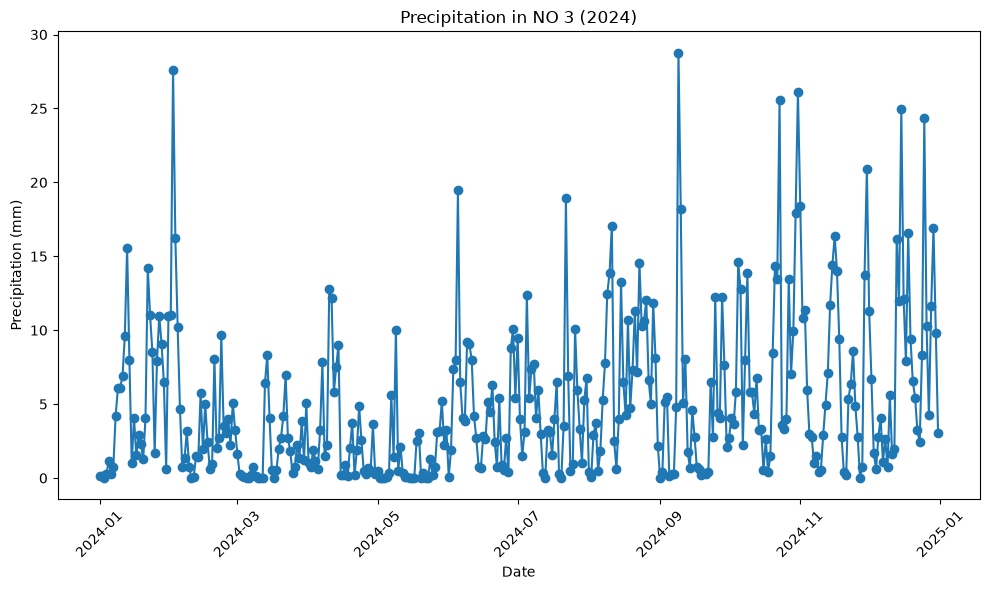

In [63]:

# Plot the average precipitation as a function of time
plt.figure(figsize=(10, 6))
plt.plot(average_precipitation["date"], average_precipitation["precipitation"], marker="o", linestyle="-")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.title("Precipitation in NO 3 (2024)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## DCT

In [68]:
# Extract daily average precipitation as a NumPy array
signal = average_precipitation["precipitation"].values

# Number of observations (366 days in 2024)
N = len(signal)

# Transform the precipitation signal from the time domain to the frequency domain
dct_signal = dct(signal, type=2, norm="ortho")

In [69]:
# Choose how many low-frequency components to remove
# A higher cutoff removes more slow variations from the signal
cutoff = 10

# Make a copy of the DCT coefficients
filtered_dct = dct_signal.copy()

# Remove the first 10 coefficients (low-frequency components)
# These components mainly represent slow changes and seasonal patterns
filtered_dct[:cutoff] = 0

# Transform the filtered coefficients back to the time domain
# This gives us the high-pass filtered precipitation signal
filtered_signal = idct(filtered_dct, type=2, norm="ortho")

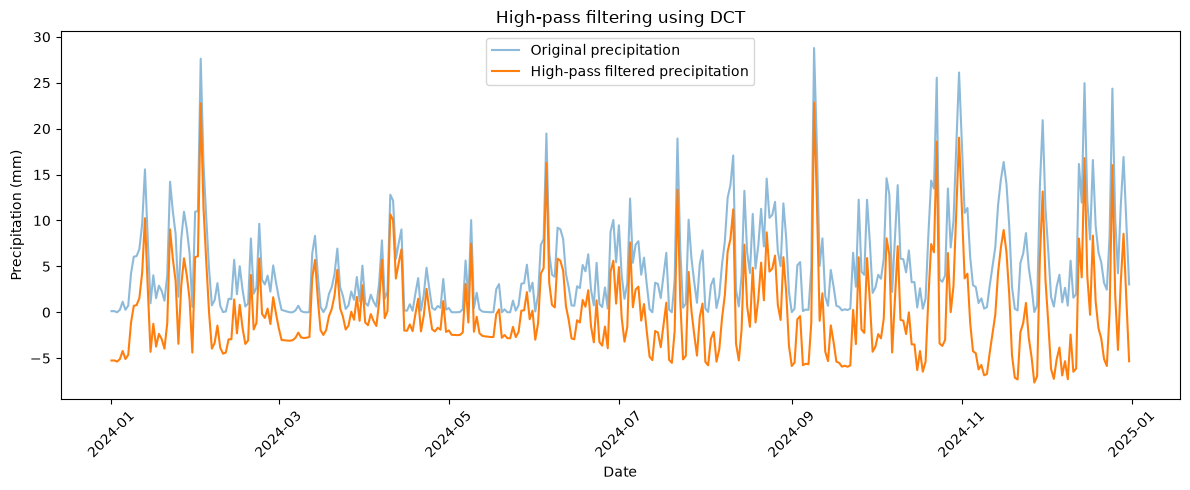

In [70]:
plt.figure(figsize=(12, 5))

# Plot the original daily average precipitation
plt.plot(
    average_precipitation["date"],
    signal,
    label="Original precipitation",
    alpha=0.5
)

# Plot the high-pass filtered precipitation
plt.plot(
    average_precipitation["date"],
    filtered_signal,
    label="High-pass filtered precipitation"
)

# Add labels and title
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.title("High-pass filtering using DCT")

# Display legend and format the x-axis
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()